# Stage 5: Temporal analysis

Annual research trends must use the original submission year, not the date of an updated arXiv version.

In [1]:
# Verifying the submission year variable is available in the final_document_clusters.csv

import pandas as pd
from pathlib import Path

base = next(
    p for p in [Path("artifacts"), Path("../artifacts")]
    if (p / "final_document_clusters.csv").exists()
)

docs = pd.read_csv(base / "final_document_clusters.csv")

temporal_cols = [
    c for c in docs.columns
    if any(s in c.lower() for s in ("year", "date", "submit"))
]

print("Temporal columns:", temporal_cols)
print("All columns:", docs.columns.tolist())

if temporal_cols:
    display(docs[temporal_cols].head(5))


Temporal columns: ['year']
All columns: ['id', 'year', 'clean_title', 'cluster_id']


,year
0,2021
1,2021
2,2021
3,2021
4,2021


## 1. Annual publication counts

In [2]:
# Annual publication distribution
annual_counts = (
    docs.groupby("year")
    .size()
    .reindex(range(2021, 2026), fill_value=0)
)

annual_summary = pd.DataFrame({
    "papers": annual_counts,
    "share_pct": (annual_counts / len(docs) * 100).round(2)
})

# Validate dataset coverage
assert annual_counts.sum() == 75110
assert annual_counts.min() > 0

print("Total papers:", annual_counts.sum())
display(annual_summary)


Total papers: 75110


,papers,share_pct
year,,
2021,8083,10.76
2022,8971,11.94
2023,13603,18.11
2024,20689,27.54
2025,23764,31.64


## 2. Identify growing and declining research topics

In [3]:
# Number of papers per cluster and year
counts = pd.crosstab(docs["cluster_id"], docs["year"])

# Share of each cluster within each year (%)
shares = counts.div(counts.sum(axis=0), axis=1) * 100

# Compare beginning and end of study period
trends = pd.DataFrame({
    "share_2021": shares[2021],
    "share_2025": shares[2025],
    "change_pp": shares[2025] - shares[2021]
})

# Add existing automatic topic descriptors
profiles = pd.read_csv(base / "final_cluster_profiles.csv")
trends = trends.join(
    profiles.set_index("cluster_id")["top_terms"]
)

print("Largest increases in relative share:")
display(trends.nlargest(8, "change_pp").round(2))

print("\nLargest decreases in relative share:")
display(trends.nsmallest(8, "change_pp").round(2))


Largest increases in relative share:


,share_2021,share_2025,change_pp,top_terms
cluster_id,,,,
149,0.02,2.66,2.63,"reasoning, models, reasoning models, thinking,..."
15,0.00,2.52,2.52,"rag, retrieval, retrieval augmented, augmented..."
19,0.25,2.35,2.10,"reward, rl, reinforcement, reinforcement learn..."
110,0.16,1.86,1.69,"agent, multi agent, multi, agents, llm, agent ..."
76,0.00,1.68,1.68,"llms, models, language, large language, langua..."
28,0.02,1.37,1.34,"safety, llms, harmful, alignment, safety align..."
25,0.01,1.34,1.33,"llm, llms, llm based, large language, large, b..."
71,0.27,1.51,1.24,"agents, agent, llm agents, llm, web, environme..."



Largest decreases in relative share:


,share_2021,share_2025,change_pp,top_terms
cluster_id,,,,
34,3.09,0.96,-2.14,"translation, machine translation, machine, mt,..."
63,2.13,0.40,-1.72,"word, words, sense, embeddings, word embedding..."
117,1.78,0.19,-1.59,"bert, model, models, bert model, bert based, b..."
60,2.05,0.53,-1.53,"question, qa, answering, question answering, a..."
38,1.78,0.37,-1.41,"summarization, summaries, abstractive, summary..."
62,1.71,0.35,-1.36,"relation, extraction, relation extraction, rel..."
151,1.42,0.17,-1.25,"pre, pre trained, trained, plms, trained langu..."
148,1.65,0.42,-1.23,"dialogue, dialogue systems, task oriented, ori..."


## 3. Visualise the development over five years

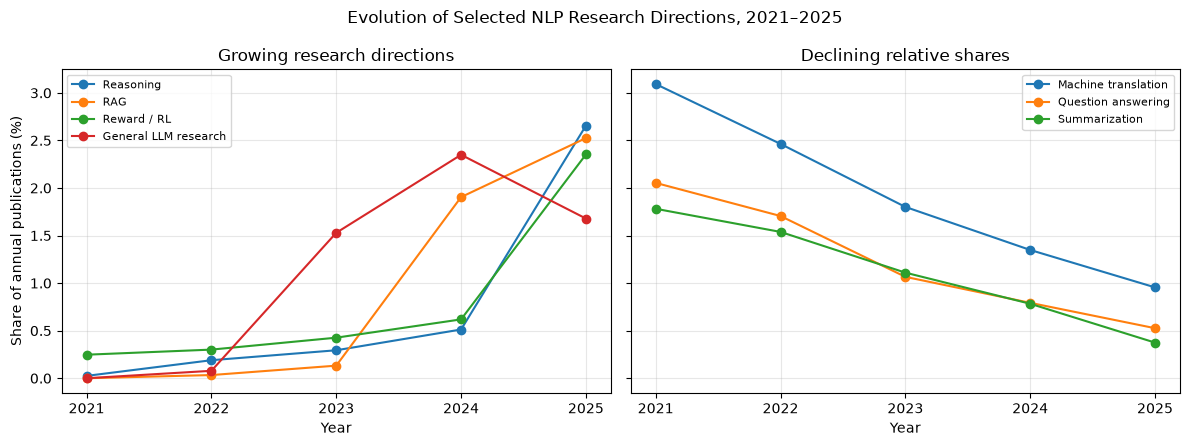

In [4]:
import matplotlib.pyplot as plt

growing = {
    149: "Reasoning",
    15: "RAG",
    19: "Reward / RL",
    76: "General LLM research"
}

declining = {
    34: "Machine translation",
    60: "Question answering",
    38: "Summarization"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, topics, title in zip(
    axes,
    [growing, declining],
    ["Growing research directions", "Declining relative shares"]
):
    for cid, label in topics.items():
        ax.plot(
            shares.columns,
            shares.loc[cid],
            marker="o",
            label=label
        )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_xticks(range(2021, 2026))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Share of annual publications (%)")

fig.suptitle("Evolution of Selected NLP Research Directions, 2021–2025")
plt.tight_layout()

plt.savefig(base / "nlp_topic_trends.png", dpi=200, bbox_inches="tight")
plt.show()


## 4. Identifying emerging and niche research topics

In [5]:
# Identify emerging and niche growing clusters

early_pct = (
    counts[[2021, 2022]].sum(axis=1)
    / counts[[2021, 2022]].to_numpy().sum() * 100
)

growth = shares[2025] - shares[2021]

sustained_growth = (
    (shares[2023] < shares[2024]) &
    (shares[2024] < shares[2025])
)

emerging = (
    (early_pct <= 0.15) &
    (shares[2025] >= 0.40) &
    sustained_growth
)

niche = (
    shares[2025].between(0.20, 0.80) &
    (growth >= 0.30) &
    sustained_growth
)

result = pd.DataFrame({
    "early_share_pct": early_pct.round(2),
    "share_2025": shares[2025].round(2),
    "growth_pp": growth.round(2),
    "papers_2025": counts[2025],
    "top_terms": profiles.set_index("cluster_id")["top_terms"]
})

print("EMERGING TOPICS:")
display(result[emerging].sort_values(
    "growth_pp", ascending=False
).head(12))

print("\nNICHE GROWING TOPICS:")
display(result[niche].sort_values(
    "growth_pp", ascending=False
).head(12))


EMERGING TOPICS:


,early_share_pct,share_2025,growth_pp,papers_2025,top_terms
cluster_id,,,,,
149,0.11,2.66,2.63,631,"reasoning, models, reasoning models, thinking,..."
15,0.02,2.52,2.52,600,"rag, retrieval, retrieval augmented, augmented..."
28,0.05,1.37,1.34,325,"safety, llms, harmful, alignment, safety align..."
25,0.01,1.34,1.33,319,"llm, llms, llm based, large language, large, b..."
14,0.11,1.27,1.15,302,"evaluation, llms, benchmark, benchmarks, model..."
55,0.05,1.08,1.08,256,"reasoning, cot, thought, chain, chain thought,..."
124,0.05,0.96,0.92,227,"hallucination, hallucinations, hallucination d..."
54,0.10,0.87,0.78,206,"long, long context, context, length, llms, mod..."
150,0.12,0.88,0.77,210,"scaling, test time, test, time, time scaling, ..."



NICHE GROWING TOPICS:


,early_share_pct,share_2025,growth_pp,papers_2025,top_terms
cluster_id,,,,,
32,0.09,0.73,0.73,173,"cot, reasoning, thought, chain, chain thought,..."
112,0.09,0.77,0.72,182,"cultural, culturally, culture, llms, cultures,..."
74,0.00,0.66,0.66,156,"kv, cache, kv cache, compression, memory, atte..."
86,0.12,0.71,0.60,169,"open, open source, source, llms, models, sourc..."
125,0.12,0.71,0.60,169,"turn, multi turn, multi, dialogue, single turn..."
83,0.16,0.63,0.57,149,"tool, tools, tool use, llms, use, tool learnin..."
11,0.13,0.61,0.48,146,"medical, clinical, patient, llms, healthcare, ..."
107,0.01,0.45,0.45,108,"unlearning, forget, machine unlearning, llm un..."
8,0.11,0.47,0.43,111,"decision, decision making, making, llms, decis..."


In [6]:
# Validate the three niche topics

selected = [74, 107, 112]
profile_lookup = profiles.set_index("cluster_id")

for cid in selected:
    print(f"\nCLUSTER {cid}")
    print("Annual counts:", counts.loc[cid].to_dict())
    print("Annual shares (%):", shares.loc[cid].round(2).to_dict())
    print("Top terms:", profile_lookup.loc[cid, "top_terms"])
    print("Representative papers:")
    print(
        profile_lookup.loc[cid, "representative_titles"]
        .replace(" | ", "\n- ")
    )



CLUSTER 74
Annual counts: {2021: 0, 2022: 0, 2023: 3, 2024: 103, 2025: 156}
Annual shares (%): {2021: 0.0, 2022: 0.0, 2023: 0.02, 2024: 0.5, 2025: 0.66}
Top terms: kv, cache, kv cache, compression, memory, attention, key value, inference, cache compression, long, context, tokens
Representative papers:
MiniCache: KV Cache Compression in Depth Dimension for Large Language Models
- D2O: Dynamic Discriminative Operations for Efficient Long-Context Inference of Large Language Models
- HCAttention: Extreme KV Cache Compression via Heterogeneous Attention Computing for LLMs

CLUSTER 107
Annual counts: {2021: 0, 2022: 1, 2023: 7, 2024: 81, 2025: 108}
Annual shares (%): {2021: 0.0, 2022: 0.01, 2023: 0.05, 2024: 0.39, 2025: 0.45}
Top terms: unlearning, forget, machine unlearning, llm unlearning, knowledge, model, forgetting, llms, data, models, methods, information
Representative papers:
A Closer Look at Machine Unlearning for Large Language Models
- Eight Methods to Evaluate Robust Unlearning 

## 5. Adding more plots to visualise temporal analysis

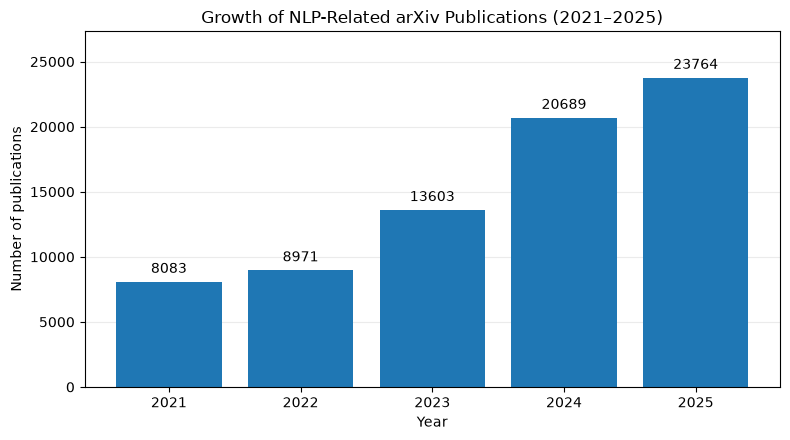

In [7]:
import matplotlib.pyplot as plt

annual = docs.groupby("year").size()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(annual.index, annual.values)

ax.bar_label(bars, fmt="%d", padding=4)
ax.set(
    title="Growth of NLP-Related arXiv Publications (2021–2025)",
    xlabel="Year",
    ylabel="Number of publications"
)
ax.set_xticks(annual.index)
ax.set_ylim(0, annual.max() * 1.15)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(base / "annual_publication_growth.png", dpi=200)
plt.show()


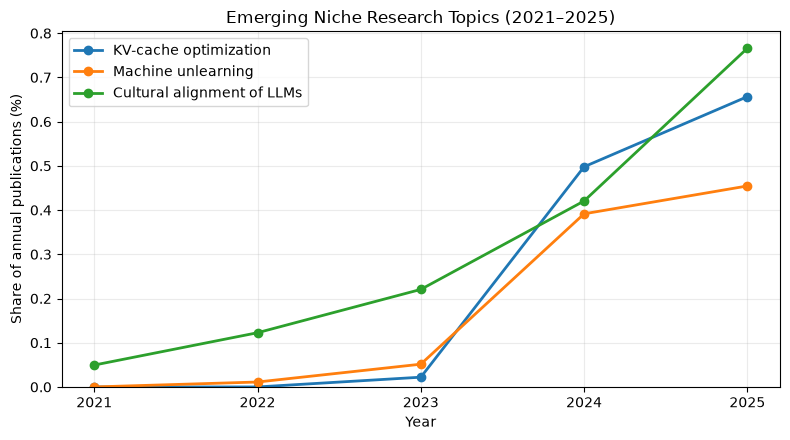

In [8]:
niche_topics = {
    74: "KV-cache optimization",
    107: "Machine unlearning",
    112: "Cultural alignment of LLMs"
}

fig, ax = plt.subplots(figsize=(8, 4.5))

for cid, label in niche_topics.items():
    ax.plot(shares.columns, shares.loc[cid],
            marker="o", linewidth=2, label=label)

ax.set(
    title="Emerging Niche Research Topics (2021–2025)",
    xlabel="Year",
    ylabel="Share of annual publications (%)"
)
ax.set_xticks(range(2021, 2026))
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig(base / "emerging_niche_topics.png", dpi=200)
plt.show()


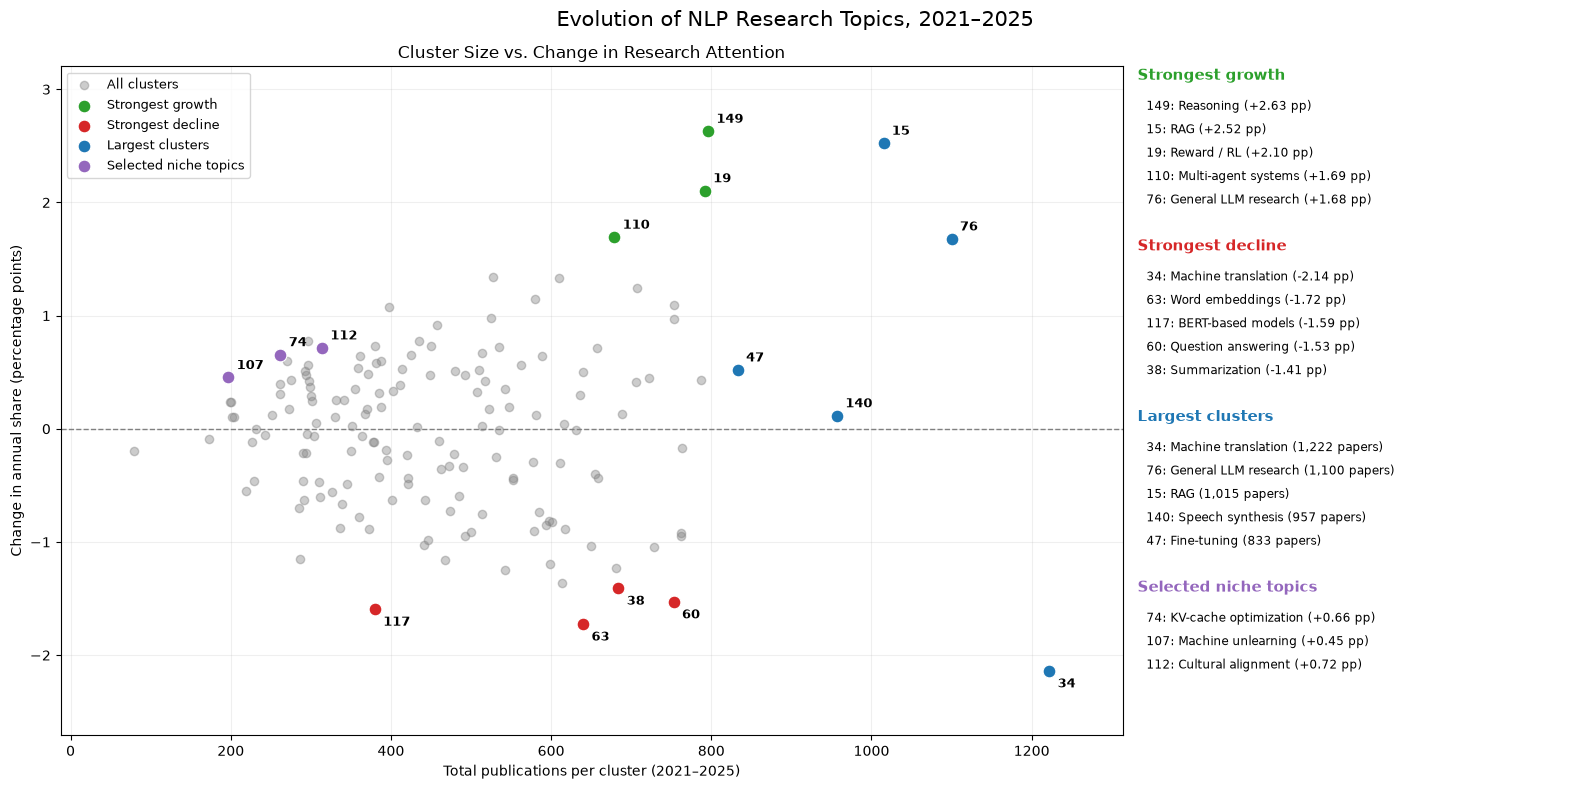

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Existing results
sizes = counts.sum(axis=1)
change = shares[2025] - shares[2021]

# Select noteworthy clusters automatically
largest = sizes.nlargest(5).index.tolist()
growing = change.nlargest(5).index.tolist()
declining = change.nsmallest(5).index.tolist()
niche = [74, 107, 112]

# Short labels for highlighted clusters
names = {
    34: "Machine translation",
    76: "General LLM research",
    15: "RAG",
    140: "Speech synthesis",
    47: "Fine-tuning",
    149: "Reasoning",
    19: "Reward / RL",
    110: "Multi-agent systems",
    63: "Word embeddings",
    117: "BERT-based models",
    60: "Question answering",
    38: "Summarization",
    74: "KV-cache optimization",
    107: "Machine unlearning",
    112: "Cultural alignment"
}

fig, (ax, side) = plt.subplots(
    1, 2, figsize=(16, 8),
    gridspec_kw={"width_ratios": [3.6, 1.5]}
)

# All clusters
ax.scatter(sizes, change, s=36, alpha=0.4,
           color="gray", label="All clusters")

categories = [
    ("Strongest growth", growing, "tab:green"),
    ("Strongest decline", declining, "tab:red"),
    ("Largest clusters", largest, "tab:blue"),
    ("Selected niche topics", niche, "tab:purple")
]

# Highlight selected points
for title, ids, color in categories:
    ax.scatter(sizes.loc[ids], change.loc[ids],
               s=85, color=color, edgecolor="white",
               linewidth=0.8, label=title, zorder=3)

# Annotate selected points using cluster IDs
selected = set(largest + growing + declining + niche)

for cid in selected:
    ax.annotate(
        str(cid),
        (sizes.loc[cid], change.loc[cid]),
        xytext=(6, 6 if change.loc[cid] >= 0 else -12),
        textcoords="offset points",
        fontsize=9, fontweight="bold"
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set(
    title="Cluster Size vs. Change in Research Attention",
    xlabel="Total publications per cluster (2021–2025)",
    ylabel="Change in annual share (percentage points)"
)
ax.grid(alpha=0.2)
ax.legend(loc="upper left", fontsize=9)
ax.margins(x=0.08, y=0.12)

# Topic key on the right
side.axis("off")
y = 0.98

for title, ids, color in categories:
    side.text(0, y, title, fontsize=11,
              fontweight="bold", color=color,
              transform=side.transAxes)
    y -= 0.045

    for cid in ids:
        name = names.get(cid, f"Cluster {cid}")
        value = (
            f"{sizes.loc[cid]:,} papers"
            if title == "Largest clusters"
            else f"{change.loc[cid]:+.2f} pp"
        )
        side.text(
            0.02, y, f"{cid}: {name} ({value})",
            fontsize=8.8, transform=side.transAxes
        )
        y -= 0.035
    y -= 0.035

fig.suptitle(
    "Evolution of NLP Research Topics, 2021–2025",
    fontsize=15
)
plt.tight_layout()
plt.savefig(base / "cluster_size_vs_trend_annotated.png",
            dpi=200, bbox_inches="tight")
plt.show()
